# Evaluación y validación de modelos

Comparación reproducible de modelos para clasificar sentimiento en comentarios sobre aerolíneas. El análisis se ejecuta con los módulos del proyecto y genera resultados, gráficas y el reporte técnico.

## Ejecución local o en Google Colab

En local, abre este notebook desde la carpeta del proyecto para que encuentre `src/` y `Tweets.csv`. En Colab, ejecuta la celda siguiente para instalar dependencias y después carga los tres scripts y `Tweets.csv` cuando se solicite.

In [1]:
%pip -q install pandas numpy scikit-learn matplotlib scipy python-docx


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys
import shutil

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'evaluacion_modelos.py').exists() and (PROJECT_ROOT.parent / 'src' / 'evaluacion_modelos.py').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if EN_COLAB:
    (PROJECT_ROOT / 'src').mkdir(exist_ok=True)
    required = ['evaluacion_modelos.py', 'prueba_ab.py', 'generar_reporte.py']
    missing = [name for name in required if not (PROJECT_ROOT / 'src' / name).exists()]
    if missing:
        uploaded = files.upload()
        for name in uploaded:
            if name in required:
                shutil.move(name, PROJECT_ROOT / 'src' / name)
    if not (PROJECT_ROOT / 'Tweets.csv').exists():
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith('.csv'):
                shutil.move(name, PROJECT_ROOT / 'Tweets.csv')

DATA_PATH = PROJECT_ROOT / 'Tweets.csv'
OUTPUT_DIR = PROJECT_ROOT / 'resultados'
OUTPUT_DIR.mkdir(exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f'No se encontró {DATA_PATH}')
sys.path.insert(0, str(PROJECT_ROOT))
print('Carpeta del proyecto:', PROJECT_ROOT)
print('Dataset:', DATA_PATH)

Carpeta del proyecto: C:\Users\pqm95\OneDrive\Documentos\Actividad6
Dataset: C:\Users\pqm95\OneDrive\Documentos\Actividad6\Tweets.csv


## 1. Inspección y preparación de datos

In [3]:
import json
import pandas as pd
from IPython.display import display, Image, FileLink
from src.evaluacion_modelos import load_and_clean, grouped_holdout, make_models, run_evaluation, mcnemar
from src.prueba_ab import simulate_ab, analyze_real_csv
from src.generar_reporte import build_report

raw = pd.read_csv(DATA_PATH)
schema = pd.DataFrame({'tipo': raw.dtypes.astype(str), 'faltantes': raw.isna().sum()})
print(f'Registros: {len(raw):,}; columnas: {raw.shape[1]}')
display(schema)
display(raw['airline_sentiment'].value_counts(dropna=False).rename_axis('clase').to_frame('registros'))
print('Filas duplicadas completas:', int(raw.duplicated().sum()))
print('Filas con texto repetido:', int(raw['text'].duplicated().sum()))
conflicts = raw.dropna(subset=['text', 'airline_sentiment']).groupby('text')['airline_sentiment'].nunique().gt(1).sum()
print('Textos con etiquetas contradictorias:', int(conflicts))

Registros: 14,640; columnas: 15


,tipo,faltantes
tweet_id,int64,0
airline_sentiment,str,0
airline_sentiment_confidence,float64,0
negativereason,str,5462
negativereason_confidence,float64,4118
airline,str,0
airline_sentiment_gold,str,14600
name,str,0
negativereason_gold,str,14608
retweet_count,int64,0


,registros
clase,
negative,9178
neutral,3099
positive,2363


Filas duplicadas completas: 36
Filas con texto repetido: 213
Textos con etiquetas contradictorias: 25


In [4]:
clean, diagnostics = load_and_clean(DATA_PATH)
audit = pd.DataFrame([
    ('Registros antes', diagnostics['records_before']),
    ('Registros después', diagnostics['records_after']),
    ('Textos vacíos', diagnostics['empty_text']),
    ('Grupos con etiquetas contradictorias', diagnostics['conflicting_text_groups']),
    ('Filas contradictorias excluidas', diagnostics['conflicting_rows_excluded']),
    ('Textos repetidos reducidos', diagnostics['duplicate_text_rows_removed']),
], columns=['diagnóstico', 'valor'])
display(audit)
display(clean['airline_sentiment'].value_counts().rename_axis('clase').to_frame('registros limpios'))

,diagnóstico,valor
0,Registros antes,14640
1,Registros después,14402
2,Textos vacíos,0
3,Grupos con etiquetas contradictorias,25
4,Filas contradictorias excluidas,57
5,Textos repetidos reducidos,181


,registros limpios
clase,
negative,9079
neutral,3046
positive,2277


## 2. Partición agrupada y modelos

La semilla fija es 42. La división agrupa por texto y estratifica por sentimiento para impedir que un mismo comentario aparezca en entrenamiento y prueba.

In [5]:
train_idx, test_idx = grouped_holdout(clean)
train = clean.iloc[train_idx]
test = clean.iloc[test_idx]
shared = set(train['text']) & set(test['text'])
assert not shared
split_table = pd.DataFrame([
    {'partición': 'Entrenamiento', 'filas': len(train), **train['airline_sentiment'].value_counts().to_dict()},
    {'partición': 'Prueba', 'filas': len(test), **test['airline_sentiment'].value_counts().to_dict()}
])
display(split_table.fillna(0))
print('Textos compartidos:', len(shared))
print('Semilla:', diagnostics['seed'])

,partición,filas,negative,neutral,positive
0,Entrenamiento,11521,7263,2436,1822
1,Prueba,2881,1816,610,455


Textos compartidos: 0
Semilla: 42


In [6]:
models = make_models()
pipeline_details = []
for name, pipeline in models.items():
    estimator = pipeline.named_steps['model']
    pipeline_details.append({
        'modelo': name,
        'transformación': type(pipeline.named_steps['tfidf']).__name__,
        'clasificador': type(estimator).__name__,
        'parámetros principales': str({k: v for k, v in estimator.get_params().items() if k in ['strategy', 'C', 'max_iter', 'n_estimators', 'max_depth', 'class_weight']})
    })
display(pd.DataFrame(pipeline_details))

,modelo,transformación,clasificador,parámetros principales
0,DummyClassifier,TfidfVectorizer,DummyClassifier,{'strategy': 'most_frequent'}
1,Regresión logística,TfidfVectorizer,LogisticRegression,"{'C': 2.0, 'class_weight': 'balanced', 'max_it..."
2,Random Forest,TfidfVectorizer,RandomForestClassifier,"{'class_weight': 'balanced_subsample', 'max_de..."


## 3. Evaluación y validación cruzada

TF-IDF se ajusta dentro de cada pipeline y de cada fold. La evaluación completa genera matrices, reportes por clase, curvas ROC, análisis de umbral y los archivos exportables.

In [7]:
summary = run_evaluation(DATA_PATH, OUTPUT_DIR)
print('Modelo con mayor F1 macro observado:', summary['best_by_macro_f1'])
print('Partición:', summary['diagnostics']['partition'])

Modelo con mayor F1 macro observado: Regresión logística
Partición: {'train_rows': 11521, 'test_rows': 2881, 'seed': 42, 'train_class_distribution': {'negative': 7263, 'neutral': 2436, 'positive': 1822}, 'test_class_distribution': {'negative': 1816, 'neutral': 610, 'positive': 455}, 'shared_texts': 0}


In [8]:
metrics = pd.read_csv(OUTPUT_DIR / 'metricas_modelos.csv')
cv = pd.read_csv(OUTPUT_DIR / 'validacion_cruzada.csv')
display(metrics)
display(cv[['model', 'f1_macro_mean', 'f1_macro_std', 'f1_macro_min', 'f1_macro_max', 'accuracy_mean']])

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Regresión logística,0.802846,0.745962,0.756914,0.750955,0.805206
1,Random Forest,0.758070,0.693987,0.714047,0.701904,0.763700
2,DummyClassifier,0.630337,0.210112,0.333333,0.257753,0.487414


,model,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max,accuracy_mean
0,DummyClassifier,0.257773,0.000055,0.257721,0.257830,0.630414
1,Regresión logística,0.744446,0.008004,0.733253,0.753001,0.797066
2,Random Forest,0.698027,0.012574,0.677886,0.708535,0.753059


## 4. Resultados por clase y matrices de confusión

reporte_clases_logistica.csv


,precision,recall,f1-score,support
negative,0.892999,0.863987,0.878254,1816.0
neutral,0.615038,0.670492,0.641569,610.0
positive,0.729847,0.736264,0.733042,455.0


reporte_clases_random_forest.csv


,precision,recall,f1-score,support
negative,0.878194,0.813877,0.844813,1816.0
neutral,0.545703,0.655738,0.595681,610.0
positive,0.658065,0.672527,0.665217,455.0


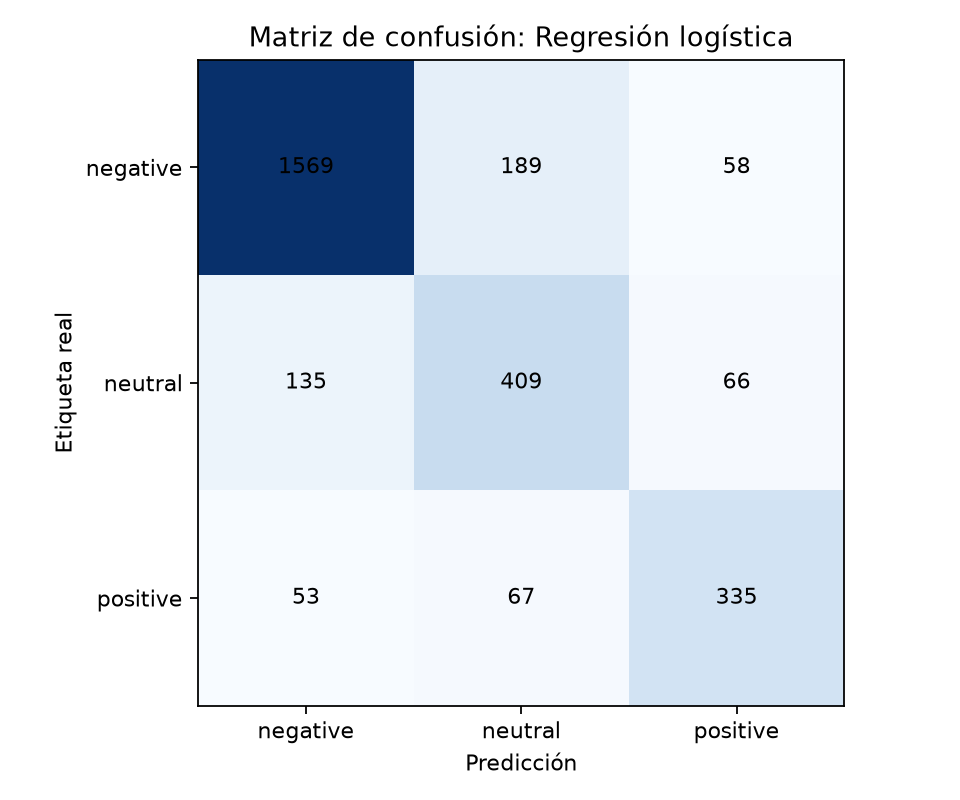

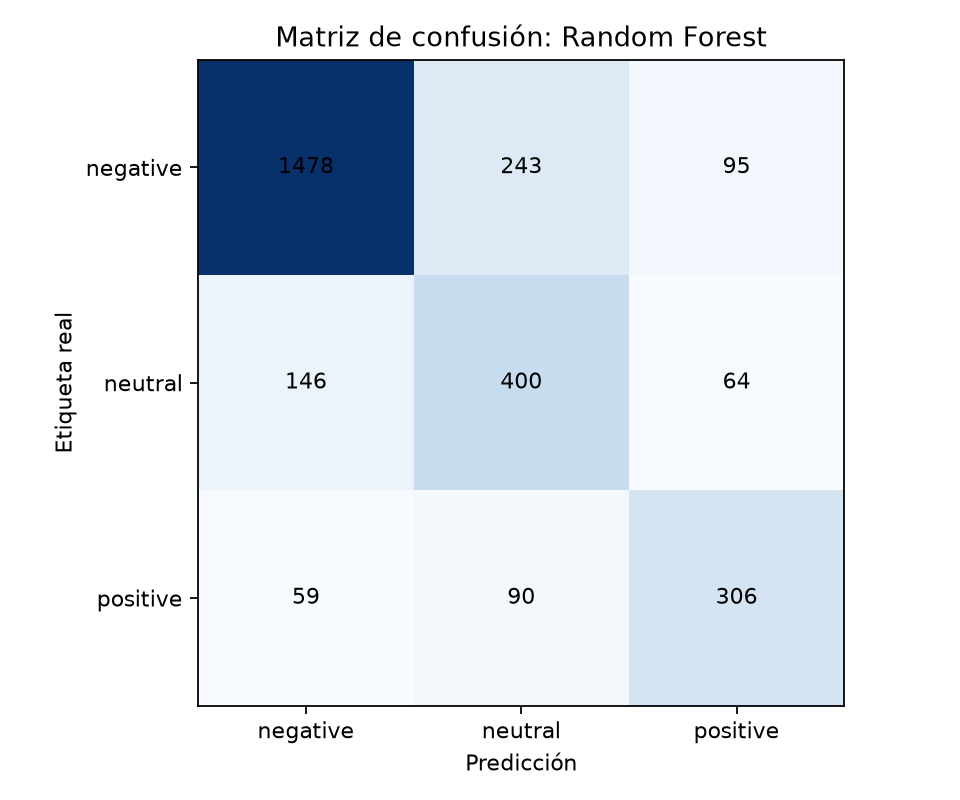

In [9]:
for filename in ['reporte_clases_logistica.csv', 'reporte_clases_random_forest.csv']:
    print(filename)
    display(pd.read_csv(OUTPUT_DIR / filename, index_col=0).loc[['negative', 'neutral', 'positive']])
for filename in ['matriz_confusion_logistica.png', 'matriz_confusion_random_forest.png']:
    display(Image(filename=str(OUTPUT_DIR / filename)))

## 5. Curvas ROC multiclase OvR

AUC macro OvR:
Regresión Logística: 0.9178
Random Forest: 0.8821


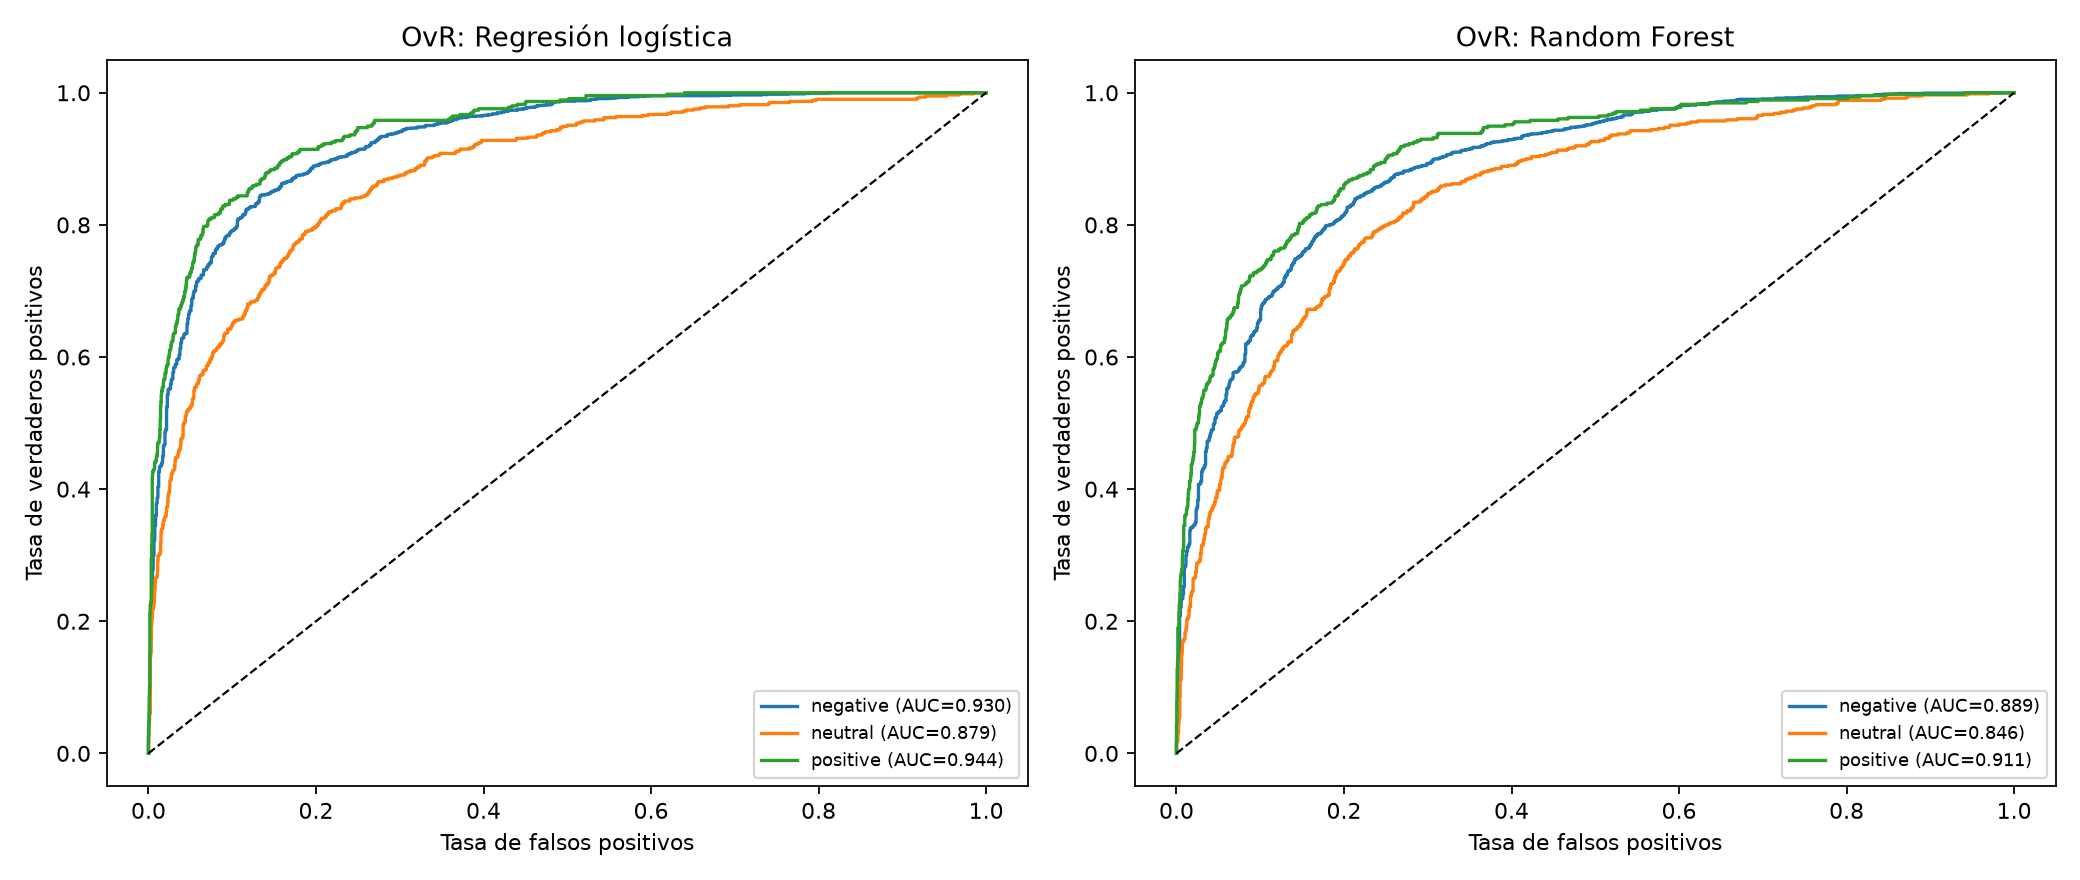

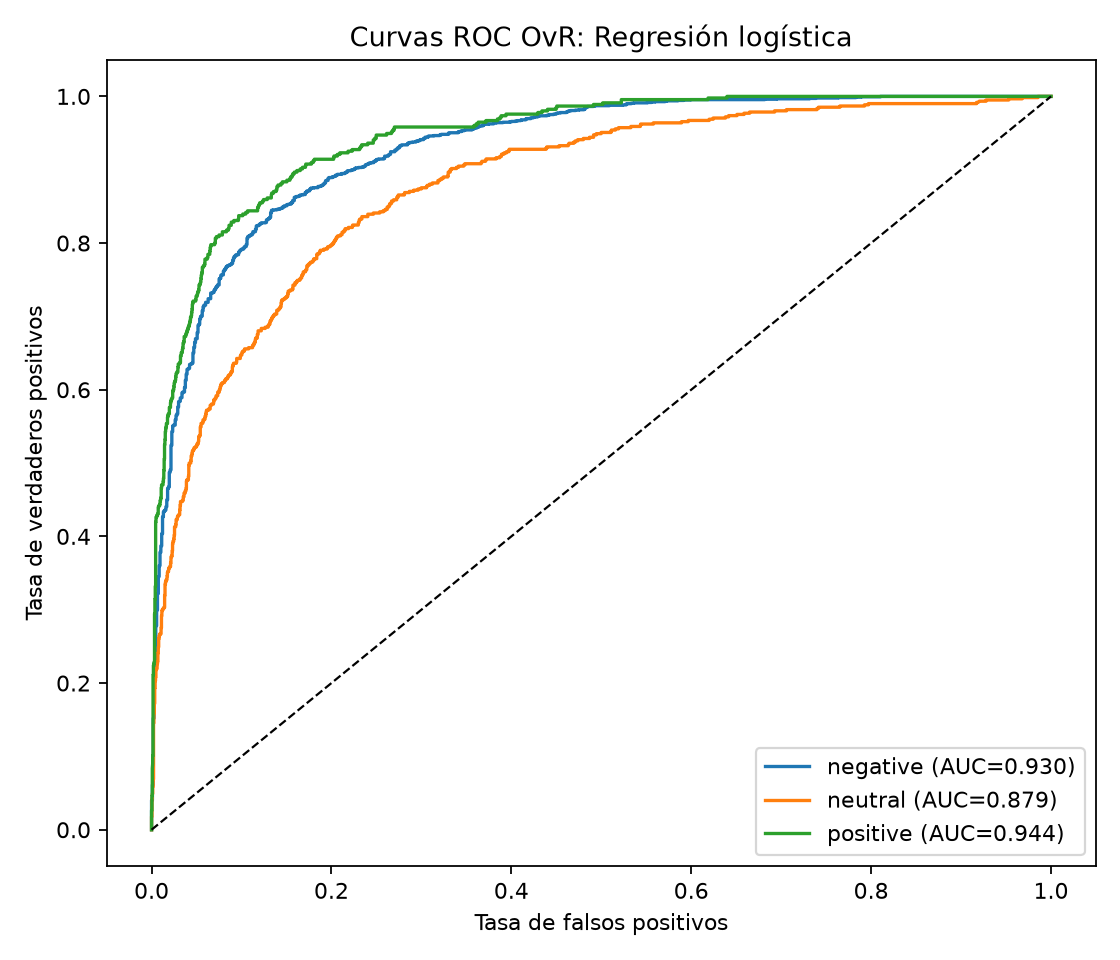

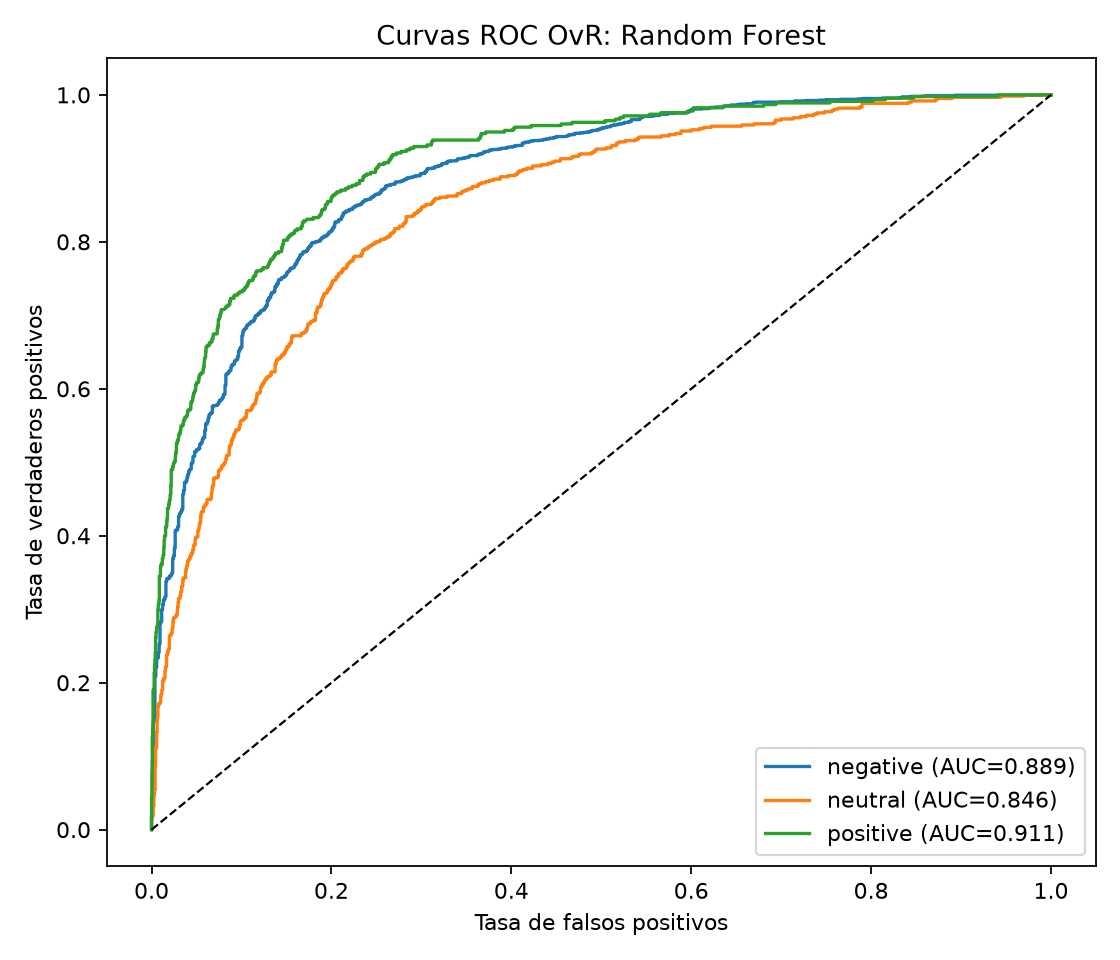

In [10]:
print('AUC macro OvR:')
print('Regresión Logística:', round(summary['statistics']['auc_ovr_macro_logistic'], 4))
print('Random Forest:', round(summary['statistics']['auc_ovr_macro_random_forest'], 4))
display(Image(filename=str(OUTPUT_DIR / 'curvas_roc.png')))
display(Image(filename=str(OUTPUT_DIR / 'curvas_roc_logistica.png')))
display(Image(filename=str(OUTPUT_DIR / 'curvas_roc_random_forest.png')))


## 6. Umbral para detectar comentarios negativos

La comparación de umbrales es exploratoria en el holdout. Si se adopta un umbral, debe fijarse antes de evaluarlo en un conjunto independiente.

Selecci?n en validaci?n out-of-fold: F1 binario m?ximo
Umbral recomendado: 0.3


,threshold,precision,recall,f1,false_positives,false_negatives
0,0.3,0.837261,0.929368,0.880914,1312,513
1,0.4,0.877436,0.880215,0.878823,893,870
2,0.5,0.908445,0.810134,0.856477,593,1379
3,0.6,0.932977,0.720639,0.813175,376,2029
4,0.7,0.954085,0.609390,0.743741,213,2837


Rendimiento final por umbral en el holdout:


,threshold,precision,recall,f1,false_positives,false_negatives
0,0.3,0.851331,0.933370,0.890465,296,121
1,0.4,0.885228,0.887665,0.886445,209,204
2,0.5,0.919266,0.827643,0.871052,132,313
3,0.6,0.944290,0.746696,0.833948,80,460
4,0.7,0.959638,0.641520,0.768977,49,651


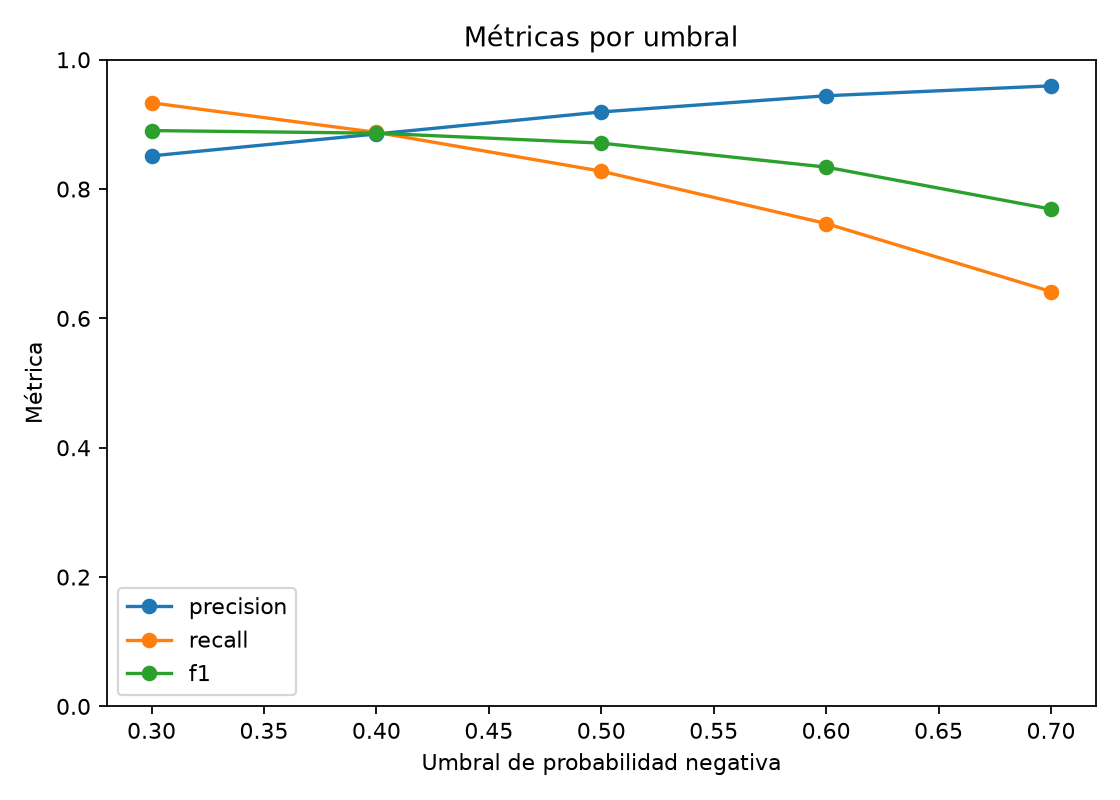

Proyecci?n ilustrativa para 1,000 comentarios:


,measure,value,interpretation
0,volume,1000,"Observed holdout prevalence, recall and false-..."
1,threshold,0.3,"Observed holdout prevalence, recall and false-..."
2,basis,"Observed holdout prevalence, recall and false-...","Observed holdout prevalence, recall and false-..."
3,holdout_negative_prevalence,0.6303366886497744,"Observed holdout prevalence, recall and false-..."
4,observed_recall,0.9333700440528634,"Observed holdout prevalence, recall and false-..."
5,observed_false_positive_rate,0.27793427230046946,"Observed holdout prevalence, recall and false-..."
6,projected_negative_detected,588,"Observed holdout prevalence, recall and false-..."
7,projected_negative_missed,42,"Observed holdout prevalence, recall and false-..."
8,projected_false_alerts,103,"Observed holdout prevalence, recall and false-..."
9,projected_alerts_for_review,691,"Observed holdout prevalence, recall and false-..."


In [11]:
thresholds = pd.read_csv(OUTPUT_DIR / 'analisis_umbral.csv')
validation_thresholds = pd.read_csv(OUTPUT_DIR / 'validacion_umbral.csv')
print('Selecci?n en validaci?n out-of-fold: F1 binario m?ximo')
print('Umbral recomendado:', summary['statistics']['recommended_negative_threshold'])
display(validation_thresholds)
print('Rendimiento final por umbral en el holdout:')
display(thresholds)
display(Image(filename=str(OUTPUT_DIR / 'analisis_umbral.png')))
print('Proyecci?n ilustrativa para 1,000 comentarios:')
display(pd.read_csv(OUTPUT_DIR / 'impacto_ilustrativo_1000.csv'))

## 7. Comparación emparejada con McNemar

In [12]:
stats = summary['statistics']
contingency = pd.DataFrame(
    [[stats['contingency_correct_both'], stats['contingency_forest_only']],
     [stats['contingency_logistic_only'], stats['contingency_both_wrong']]],
    index=['Random Forest correcto', 'Random Forest incorrecto'],
    columns=['Logística correcta', 'Logística incorrecta']
)
display(contingency)
print('Chi-cuadrado con corrección de continuidad:', round(stats['mcnemar_chi2_cc'], 4))
print('Valor p exacto:', stats['mcnemar_exact_p'])
print('McNemar compara errores emparejados; no constituye una prueba A/B operativa.')

,Logística correcta,Logística incorrecta
Random Forest correcto,2029,155
Random Forest incorrecto,284,413


Chi-cuadrado con corrección de continuidad: 37.3212
Valor p exacto: 7.623333919649303e-10
McNemar compara errores emparejados; no constituye una prueba A/B operativa.


## 8. SIMULACIÓN CON DATOS SINTÉTICOS

La simulación demuestra el procedimiento con supuestos editables. Sus resultados no son evidencia de operación real.

,grupo,casos_total,negativos_reales,negativos_detectados,recall,alertas_falsas,precision_alertas
0,A,1097,329,216,0.656535,144,0.600000
1,B,1097,329,237,0.720365,175,0.575243


,recall_a,recall_b,difference_b_minus_a,z_statistic,p_value,confidence_interval_95
0,0.656535,0.720365,0.06383,1.76769,0.077113,"[-0.006775, 0.134434]"


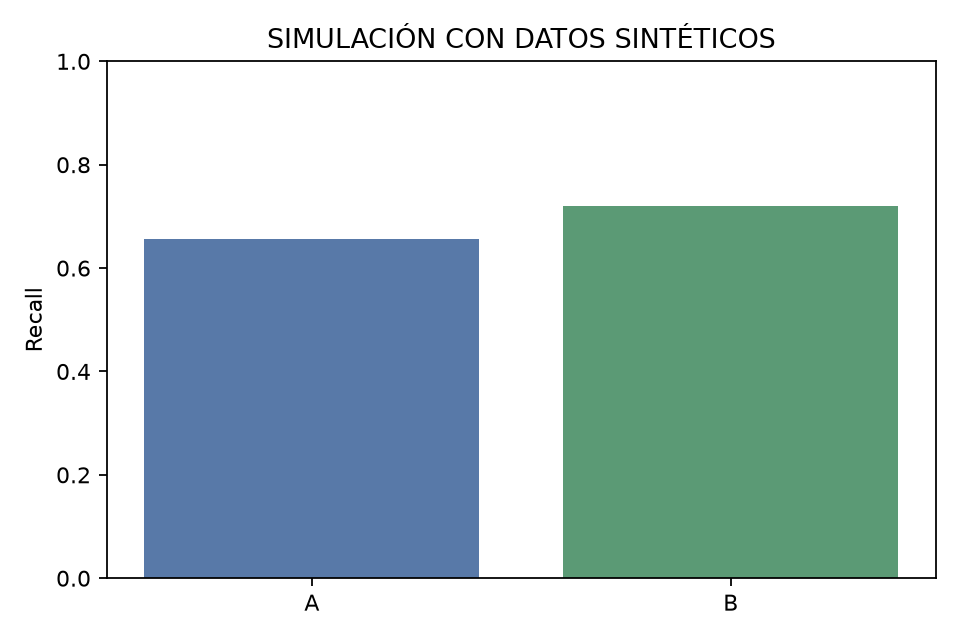

Tamaño estimado por grupo (casos negativos): 329


In [13]:
import subprocess
subprocess.run([sys.executable, '-m', 'src.prueba_ab', '--output', str(OUTPUT_DIR)], cwd=PROJECT_ROOT, check=True)
ab_table = pd.read_csv(OUTPUT_DIR / 'simulacion_ab_sintetica.csv')
ab_summary = json.loads((OUTPUT_DIR / 'simulacion_ab_sintetica.json').read_text(encoding='utf-8'))
display(ab_table)
display(pd.DataFrame([ab_summary['test']]))
display(Image(filename=str(OUTPUT_DIR / 'simulacion_ab_sintetica.png')))
print('Tamaño estimado por grupo (casos negativos):', ab_summary['estimated_n_negative_per_group'])

## 9. Analizador opcional para una prueba A/B real

In [14]:
REAL_AB_PATH = PROJECT_ROOT / 'datos_ab_operativos.csv'
if REAL_AB_PATH.exists():
    real_table, real_test = analyze_real_csv(REAL_AB_PATH)
    display(real_table)
    display(pd.DataFrame([real_test]))
else:
    print('Pendiente: no se proporcionó datos_ab_operativos.csv. La plantilla vacía está en plantillas/plantilla_ab_real.csv.')

Pendiente: no se proporcionó datos_ab_operativos.csv. La plantilla vacía está en plantillas/plantilla_ab_real.csv.


## 10. Generación del reporte y archivos finales

In [15]:
report_path = build_report(str(OUTPUT_DIR), str(PROJECT_ROOT / 'reporte' / 'Reporte_Tecnico_Evaluacion_Validacion.docx'))
display(FileLink(str(report_path)))
artifacts = sorted(str(path.relative_to(PROJECT_ROOT)) for path in OUTPUT_DIR.iterdir())
display(pd.DataFrame({'archivos generados': artifacts}))

C:\Users\pqm95\OneDrive\Documentos\Actividad6\reporte\Reporte_Tecnico_Evaluacion_Validacion.docx

,archivos generados
0,resultados\analisis_umbral.csv
1,resultados\analisis_umbral.png
2,resultados\curvas_roc.png
3,resultados\curvas_roc_logistica.png
4,resultados\curvas_roc_random_forest.png
5,resultados\impacto_ilustrativo_1000.csv
6,resultados\impacto_ilustrativo_1000.json
7,resultados\matriz_confusion_logistica.csv
8,resultados\matriz_confusion_logistica.png
9,resultados\matriz_confusion_random_forest.csv


## Interpretación final

Interpreta el F1 macro junto con las métricas por clase, la validación cruzada y los errores de las matrices. La simulación A/B permanece identificada como sintética; el analizador de una prueba real requiere observaciones operativas con etiquetas independientes.